In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [39]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/processed/SeoulBikeData_clean.csv")
if not data_path.exists():
    data_path = Path("data/processed/SeoulBikeData_clean.csv")

print("Читаем:", data_path.resolve())

df = pd.read_csv(data_path, parse_dates=["Date"])

print("Размер:", df.shape)
print("dtype Date:", df["Date"].dtype)   
df.head()

Читаем: E:\04_gradient_boosting\data\processed\SeoulBikeData_clean.csv
Размер: (8760, 14)
dtype Date: datetime64[us]


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## Подготовка признаков и разделение данных

Цель: выделить `X` и `y`, затем разделить данные **по времени**
на обучающую (80%) и тестовую (20%) части.

In [40]:

df = df.sort_values(["Date", "Hour"]).reset_index(drop=True)

df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.day_of_week

y = df["Rented Bike Count"]

X = df.drop(columns=["Rented Bike Count", "Date"])

assert "Rented Bike Count" not in X.columns

split = int(len(df) * 0.8)

X_train = X.iloc[:split].copy()
X_test  = X.iloc[split:].copy()
y_train = y.iloc[:split].copy()
y_test  = y.iloc[split:].copy()

print("TRAIN:", X_train.shape, y_train.shape)
print("TEST :", X_test.shape, y_test.shape)
print("Последняя дата TRAIN:", df.iloc[split - 1]["Date"].date())
print("Первая дата TEST :", df.iloc[split]["Date"].date())
print("\nПризнаки:", X.columns.tolist())

TRAIN: (7008, 14) (7008,)
TEST : (1752, 14) (1752,)
Последняя дата TRAIN: 2018-09-18
Первая дата TEST : 2018-09-19

Признаки: ['Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day', 'month', 'day_of_week']


## Обучение и оценка Gradient Boosting

Обучаем `GradientBoostingRegressor` на TRAIN, оцениваем на TEST.

Гиперпараметры:
- `n_estimators=300` — количество деревьев
- `learning_rate=0.05` — вклад каждого дерева
- `max_depth=4` — глубина дерева
- `subsample=0.8` — доля объектов для каждого дерева (стохастичность)
- `random_state=42` — воспроизводимость
Метрики: **MAE**, **RMSE**, **R²**.

После предсказания применяем `clip` — спрос не может быть отрицательным.

In [41]:
categorical_features = ["Seasons", "Holiday", "Functioning Day"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

gbr_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        random_state=42,
    )),
])

gbr_pipeline.fit(X_train, y_train)
print("Pipeline обучен")
print(gbr_pipeline)

Pipeline обучен
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Hour', 'Temperature(°C)',
                                                   'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Dew point temperature(°C)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'Rainfall(mm)',
                                                   'Snowfall (cm)', 'month',
                                                   'day_of_week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Seasons', 'Holiday',

In [42]:
# clip: спрос не может быть отрицательным (у модели были прогнозы < 0)
y_pred_raw = gbr_pipeline.predict(X_test)
y_pred = np.clip(y_pred_raw, 0, None)

mae  = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)   
r2   = r2_score(y_test, y_pred)

print(f"MAE  = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R²   = {r2:.4f}")
print(f"Мин. предсказание до clip: {y_pred_raw.min():.1f}")
print(f"Мин. предсказание после clip: {y_pred.min():.1f}")

MAE  = 191.24
RMSE = 282.52
R²   = 0.7878
Мин. предсказание до clip: -548.0
Мин. предсказание после clip: 0.0


## Сравнение реальных и предсказанных значений


In [43]:
comparison = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred.round().astype(int),
    "error": (y_pred - y_test).round().astype(int)
})
comparison["abs_error"] = comparison["error"].abs()
comparison.head(10)

,actual,predicted,error,abs_error
7008,0,0,0,0
7009,0,0,0,0
7010,0,0,0,0
7011,0,0,0,0
7012,0,0,0,0
7013,0,0,0,0
7014,0,0,0,0
7015,0,0,0,0
7016,0,280,280,280
7017,0,0,0,0


In [44]:
print("Самые большие ошибки:")
comparison.sort_values("abs_error", ascending=False).head(10)

Самые большие ошибки:


,actual,predicted,error,abs_error
7530,2514,1334,-1180,1180
7314,2857,1687,-1170,1170
8418,1956,789,-1167,1167
8490,1904,804,-1100,1100
7578,2618,1521,-1097,1097
7866,2612,1529,-1083,1083
7554,2378,1316,-1062,1062
8010,2074,1015,-1059,1059
8034,2094,1050,-1044,1044
7842,2415,1372,-1043,1043


## Визуализация: Actual vs Predicted

Каждая точка — один час тестового периода.
Красная пунктирная линия — идеальное совпадение (`y_pred = y_true`).

Если точки лежат ниже линии — модель занижает спрос,
выше — завышает.

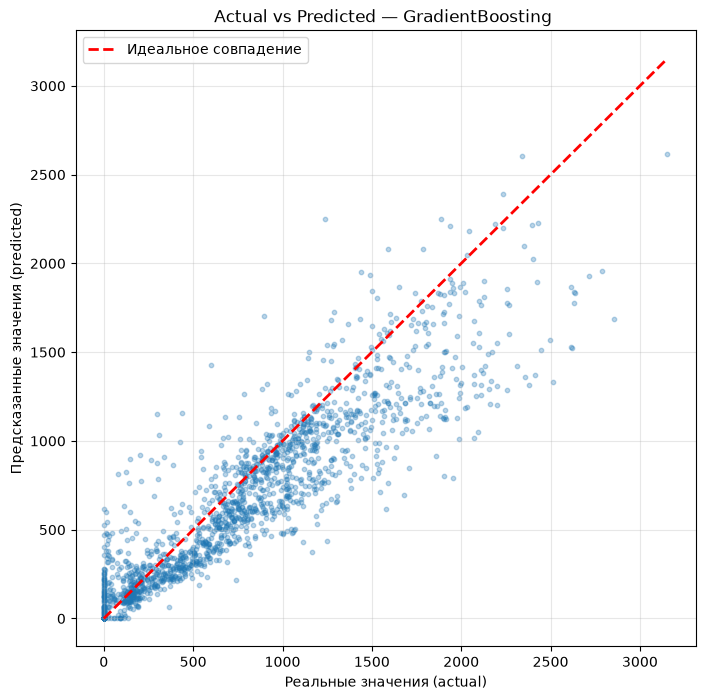

In [45]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([0, y_test.max()], [0, y_test.max()], "r--", lw=2, label="Идеальное совпадение")
plt.xlabel("Реальные значения (actual)")
plt.ylabel("Предсказанные значения (predicted)")
plt.title("Actual vs Predicted — GradientBoosting ")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Residual plot — распределение ошибок

Остаток = `actual - predicted`.

Если модель адекватна, остатки должны быть:
- распределены примерно симметрично относительно нуля;
- без явной структуры (например, «воронки» — рост разброса с ростом прогноза).

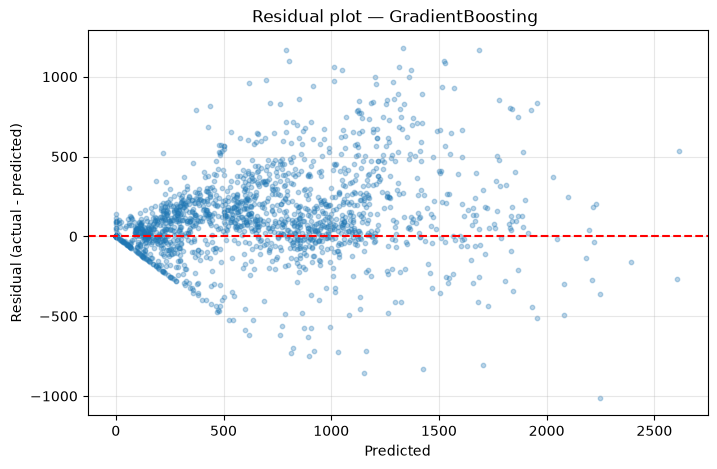

In [46]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3, s=10)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot — GradientBoosting ")
plt.grid(True, alpha=0.3)
plt.show()

## Выводы по Gradient Boosting

1. Модель **GradientBoostingRegressor** показала:
   - MAE = 191.24 — средняя ошибка около 191 велосипеда в час;
   - RMSE = 282.52 — крупные ошибки штрафуются сильнее;
   - R² = 0.7878 — модель объясняет ~79% разброса спроса.
   
2. Анализ ошибок показал, что модель **систематически занижает
   пиковые значения** спроса (реальный спрос 1900–2900, прогноз 800–1700).
   Вероятная причина — пики редки в обучающей выборке, а деревья
   усредняют прогноз.
